     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 39.5 MB/s eta 0:00:00
  Created wheel for nflows: filename=nflows-0.14-py3-none-any.whl size=53654 sha25

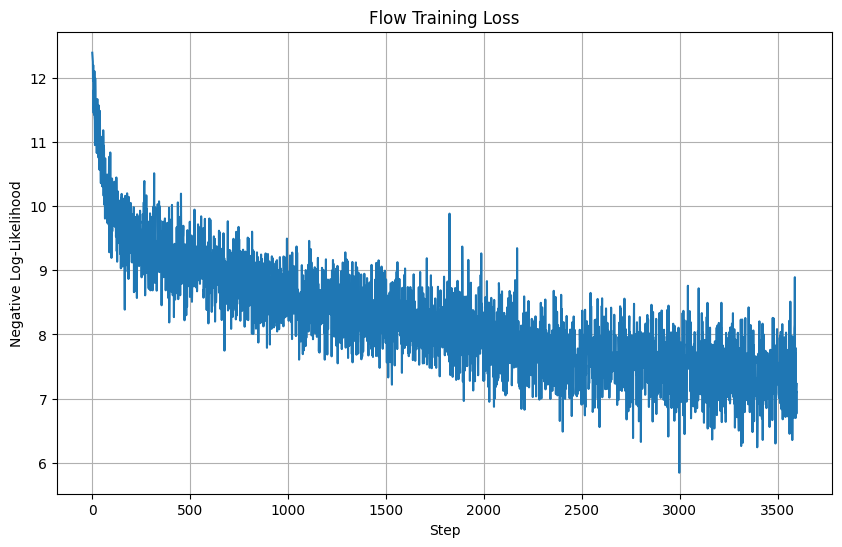

In [ ]:
!pip install nflows==0.14

import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from nflows.flows.base import Flow
from nflows.transforms import CompositeTransform, ReversePermutation, PiecewiseRationalQuadraticCouplingTransform
from nflows.nn.nets import ResidualNet
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

# Set seeds
np.random.seed(42)
torch.manual_seed(42)

# ==== 1. Generate 7D nonlinear, non-Gaussian data ====

n_samples = 2000
t = np.linspace(0, 4 * np.pi, n_samples)

# Base nonlinear signal (like a twisted spiral in 2D)
x1 = np.sin(t) + 0.1 * np.random.randn(n_samples)
x2 = np.cos(t) + 0.1 * np.random.randn(n_samples)

# Additional nonlinear features with noise and nonlinear transforms
x3 = t / (4 * np.pi) + 0.1 * np.random.randn(n_samples)  # scaled linear trend
x4 = np.sin(2 * t) * np.cos(t) + 0.1 * np.random.randn(n_samples)
x5 = np.exp(-t / (4 * np.pi)) + 0.05 * np.random.randn(n_samples)
x6 = np.tanh(t / 10) + 0.05 * np.random.randn(n_samples)
x7 = np.sin(t) * x3 + 0.05 * np.random.randn(n_samples)

data_7d = np.vstack([x1, x2, x3, x4, x5, x6, x7]).T

# Normalize data
scaler = StandardScaler()
data_7d_scaled = scaler.fit_transform(data_7d)

# ==== 2. Fit GMM ====
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm.fit(data_7d_scaled)
gmm_log_likelihood = gmm.score(data_7d_scaled) * len(data_7d_scaled)

# ==== 3. Custom Base Distribution for Flow ====
class CustomMixtureOfGaussians(torch.distributions.Distribution):
    arg_constraints = {}
    def __init__(self, means, variances, weights, input_dim=7, device='cpu'):
        super().__init__(validate_args=False)
        self.input_dim = input_dim
        self.distributions = [
            torch.distributions.MultivariateNormal(
                torch.tensor(m, dtype=torch.float32, device=device),
                torch.diag(torch.tensor(v, dtype=torch.float32, device=device))
            ) for m, v in zip(means, variances)
        ]
        self.weights = torch.tensor(weights, dtype=torch.float32, device=device)

    def log_prob(self, x, context=None):
        log_probs = torch.stack([d.log_prob(x) + torch.log(w) for d, w in zip(self.distributions, self.weights)], dim=0)
        return torch.logsumexp(log_probs, dim=0)

    def sample(self, sample_shape, context=None):
        if isinstance(sample_shape, int):
            sample_shape = (sample_shape,)
        z = torch.multinomial(self.weights, sample_shape[0], replacement=True)
        samples = torch.stack([self.distributions[i].sample(sample_shape) for i in range(len(self.distributions))])
        return samples[z, torch.arange(sample_shape[0])]

# ==== 4. Define Flow Model ====
def create_flow(input_dim=7, hidden_features=128, num_layers=6):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    transforms = []
    # Alternate masks for coupling layers
    masks = [torch.tensor([(i + j) % 2 for i in range(input_dim)], dtype=torch.float32, device=device) for j in range(num_layers)]
    for mask in masks:
        transforms.append(ReversePermutation(features=input_dim))
        transforms.append(
            PiecewiseRationalQuadraticCouplingTransform(
                mask=mask,
                transform_net_create_fn=lambda in_features, out_features: ResidualNet(
                    in_features=in_features,
                    out_features=out_features,
                    hidden_features=hidden_features,
                    num_blocks=3,
                    activation=nn.ReLU()
                ),
                tails='linear',
                num_bins=8
            )
        )
    base_dist = CustomMixtureOfGaussians(
        means=[[-1.0]*input_dim, [1.0]*input_dim],
        variances=[[1.0]*input_dim, [1.0]*input_dim],
        weights=[0.5, 0.5],
        input_dim=input_dim,
        device=device
    )
    transform = CompositeTransform(transforms)
    flow = Flow(transform, base_dist).to(device)
    return flow

# ==== 5. Training function ====
def train_flow(flow, data, steps=6000, lr=5e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    flow = flow.to(device)
    optimizer = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2000, gamma=0.5)
    data_tensor = torch.tensor(data, dtype=torch.float32).to(device)
    losses = []
    batch_size = 64
    best_loss = float('inf')
    patience = 600
    steps_without_improvement = 0
    for step in range(steps):
        idx = np.random.choice(len(data), size=batch_size, replace=False)
        batch = data_tensor[idx]
        log_prob = flow.log_prob(batch)
        loss = -log_prob.mean()
        if not torch.isfinite(loss):
            print(f"Non-finite loss at step {step}")
            break
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(flow.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        if step % 500 == 0:
            print(f"Step {step} | NLL: {loss.item():.4f}")
        if loss.item() < best_loss:
            best_loss = loss.item()
            steps_without_improvement = 0
        else:
            steps_without_improvement += 1
            if steps_without_improvement >= patience:
                print(f"Early stopping at step {step}")
                break
    flow_log_likelihood = flow.log_prob(data_tensor).sum().item()
    return flow, losses, flow_log_likelihood

# ==== 6. Train the flow ====
flow = create_flow(input_dim=7)
flow, losses, flow_log_likelihood = train_flow(flow, data_7d_scaled)

# ==== 7. KL Divergence ====
def compute_kl_divergence(real_data, generated_data):
    kl_scores = []
    for i in range(real_data.shape[1]):
        kde_real = gaussian_kde(real_data[:, i])
        kde_gen = gaussian_kde(generated_data[:, i])
        xs = np.linspace(
            min(real_data[:, i].min(), generated_data[:, i].min()),
            max(real_data[:, i].max(), generated_data[:, i].max()), 1000
        )
        p = np.clip(kde_real(xs), 1e-10, 1)
        q = np.clip(kde_gen(xs), 1e-10, 1)
        kl = np.sum(p * np.log(p / q))
        kl_scores.append(kl)
    return np.mean(kl_scores)

# ==== 8. Generate samples ====
gmm_samples_scaled = gmm.sample(len(data_7d_scaled))[0]
flow_samples_scaled = flow.sample(len(data_7d_scaled)).detach().cpu().numpy()

data_7d_original = scaler.inverse_transform(data_7d_scaled)
gmm_samples = scaler.inverse_transform(gmm_samples_scaled)
flow_samples = scaler.inverse_transform(flow_samples_scaled)

# ==== 9. Calculate KL divergences ====
gmm_kl = compute_kl_divergence(data_7d_original, gmm_samples)
flow_kl = compute_kl_divergence(data_7d_original, flow_samples)

# ==== 10. Results ====
print("\nModel Comparison:")
print(f"GMM Log-Likelihood: {gmm_log_likelihood:.4f}")
print(f"Flow Log-Likelihood: {flow_log_likelihood:.4f}")
print(f"GMM KL Divergence: {gmm_kl:.4f}")
print(f"Flow KL Divergence: {flow_kl:.4f}")

# ==== 11. Plot loss ====
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(losses)
plt.title("Flow Training Loss")
plt.xlabel("Step")
plt.ylabel("Negative Log-Likelihood")
plt.grid(True)
plt.show()
